In [1]:
import numpy as np
import pandas as pd
from utils import *
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from collections import defaultdict
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import pairwise_distances

In [2]:
#spectral_data_mpc_mpb = pd.read_csv('../processed_data/mpb_mpc_data.csv')
#del spectral_data_mpc_mpb['Unnamed: 0']

In [3]:
df_spectra_flopp = pd.read_csv('../processed_data/flopp_flopp_e_pivot.csv')
del df_spectra_flopp['Unnamed: 0']

label_table = (
    df_spectra_flopp.
    query('data_source == "flopp"').
    groupby(['polymer']).
    count()['file_name'].
    reset_index().
    reset_index().
    iloc[:,:-1])

label_table_e = (
    df_spectra_flopp.
    query('data_source == "flopp_e"').
    groupby(['polymer']).
    count()['file_name'].
    reset_index().
    reset_index().
    iloc[:,:-1])

label_table = label_table.merge(label_table_e, on='polymer')
del label_table['index_x']
del label_table['index_y']
label_table = label_table.reset_index()
label_table.columns = ['label', 'polymer']

df_spectra_flopp = df_spectra_flopp.merge(label_table)

y_train = df_spectra_flopp.query('data_source == "flopp"').iloc[:,1].to_numpy()
label_train = df_spectra_flopp.query('data_source == "flopp"').iloc[:,-1].to_numpy()
X_train = df_spectra_flopp.query('data_source == "flopp"').iloc[:,3:-1].to_numpy()
X_train = (X_train - X_train.mean(1)[:, None]) / X_train.std(1)[:, None]

y_test = df_spectra_flopp.query('data_source == "flopp_e"').iloc[:,1].to_numpy()
label_test = df_spectra_flopp.query('data_source == "flopp_e"').iloc[:,-1].to_numpy()
X_test = df_spectra_flopp.query('data_source == "flopp_e"').iloc[:,3:-1].to_numpy()
X_test = (X_test - X_test.mean(1)[:, None]) / X_test.std(1)[:, None]

wl_list = np.float64(df_spectra_flopp.columns[3:-1])

In [4]:
#df_spectra_flopp = pd.read_csv('../processed_data/flopp_flopp_e_pivot.csv')
#del df_spectra_flopp['Unnamed: 0']
(df_spectra_flopp.
 groupby(['data_source', 'polymer']).
 count().
 reset_index().
 iloc[:,:3].
 pivot(index='polymer', values='file_name', columns='data_source').reset_index())

data_source,polymer,flopp,flopp_e
0,Acrylonitrile Butadiene Styrene,14,1
1,Cotton,14,12
2,Polyamide,12,6
3,Polycarbonate,8,1
4,Polyethylene,18,49
5,Polyethylene Terephthalate,25,22
6,Polyethylene Vinyl Acetate,10,5
7,Polypropylene,19,66
8,Polystyrene,14,12
9,Polyurethane,13,6


In [5]:
#spectral_data_mpc_mpb_ = spectral_data_mpc_mpb.copy()

In [6]:
#y_test_2 = spectral_data_mpc_mpb_.loc[np.isnan(spectral_data_mpc_mpb_.merge(label_table, how='left')['label']),:]['polymer'].to_numpy()
#label_test_2 = spectral_data_mpc_mpb_.loc[np.isnan(spectral_data_mpc_mpb_.merge(label_table, how='left')['label']),:]['label'].to_numpy()
#X_test_2 = spectral_data_mpc_mpb_.loc[np.isnan(spectral_data_mpc_mpb_.merge(label_table, how='left')['label']),:].iloc[:,2:].to_numpy()
#X_test_2 = (X_test_2 - X_test_2.mean(1)[:, None]) / X_test_2.std(1)[:, None]


In [7]:
#spectral_data_mpc_mpb = spectral_data_mpc_mpb.merge(label_table)

In [8]:
smx = smx_hqi(X_train, X_test, label_train)
(np.argmax(smx, 1) == label_test).mean()
#sns.heatmap(smx)

0.8518518518518519

In [9]:
(np.argmax(smx_hqi(X_train, X_test, label_train), 1) == label_test).mean()

0.8518518518518519

In [10]:
(np.argmax(smx_hqi(X_train, X_test, label_train), 1) == np.argmax(smx_nn(X_train, X_test, label_train), 1)).mean()

1.0

In [130]:
X_train.shape

(156, 1725)

In [11]:
clf = LogisticRegression(random_state=0)#, C=1, penalty='l1', solver='saga')
clf.fit(X_train, y_train)
clf.score(X_test, y_test)

/Users/eochoa/opt/anaconda3/envs/working/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:444: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.9259259259259259

In [12]:
smx = smx_hqi(X_train, X_test, label_train)
alpha = .05
    
cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(smx, label_test, cal_prop=.8)
n = cal_smx.shape[0]

In [13]:
(prediction_sets, empirical_coverage), qhat = conform_pref(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)

In [14]:
smx2 = smx_nn(X_train, X_test, label_train)
cal_smx2, val_smx2 = smx2[idx], smx2[~idx]

In [15]:
(prediction_sets2, empirical_coverage2), qhat2 = conform_pref(cal_smx2, val_smx2, cal_labels, n, alpha, val_labels, cond=0)


In [22]:
prediction_sets.sum(1).mean()

3.9473684210526314

In [23]:
prediction_sets2.sum(1).mean()

1.8421052631578947

(array([6., 5., 4., 2., 1., 6., 3., 3., 5., 3.]),
 array([0.00075048, 0.02515908, 0.04956767, 0.07397627, 0.09838486,
        0.12279346, 0.14720205, 0.17161065, 0.19601924, 0.22042784,
        0.24483643]),
 <BarContainer object of 10 artists>)

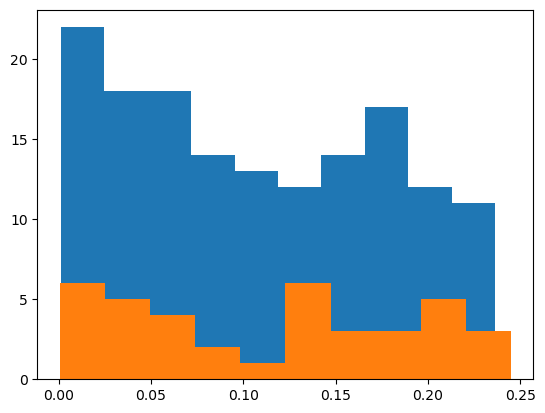

In [38]:
plt.hist(np.diff(np.sort(cal_smx, 1)[:,-2:],1).flatten())
plt.hist(np.diff(np.sort(val_smx, 1)[:,-2:],1).flatten())

In [103]:
q_rej_hat = np.quantile(np.diff(np.sort(cal_smx, 1)[:,-2:],1).flatten(),.05)

In [104]:
q_rej_hat

0.0073340510480847665

In [105]:
not_reject_val = (np.diff(np.sort(val_smx, 1)[:,-2:],1).flatten() >= q_rej_hat)
reject_val = ~not_reject_val

In [106]:
(np.argmax(val_smx, 1) != val_labels).mean()

0.10526315789473684

In [107]:
not_reject_val

array([False,  True,  True,  True,  True,  True,  True,  True,  True,
        True, False,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True, False,  True,  True,  True,  True,
        True,  True])

In [108]:
(np.argmax(val_smx[not_reject_val], 1) != val_labels[not_reject_val]).mean()

0.08571428571428572

In [109]:
(reject_val).mean()

0.07894736842105263

In [100]:
(np.argmax(val_smx[reject_val], 1) != val_labels[reject_val]).mean()

0.2857142857142857

In [129]:
c = .3
for alpha in np.linspace(0.01,.3, 20):
    q_rej_hat = np.quantile(np.diff(np.sort(cal_smx2, 1)[:,-2:],1).flatten(),alpha)
    not_reject_val = (np.diff(np.sort(val_smx2, 1)[:,-2:],1).flatten() >= q_rej_hat)
    reject_val = ~not_reject_val
    #print((np.argmax(val_smx[not_reject_val], 1) != val_labels[not_reject_val]).mean(), (reject_val).mean())
    print(alpha,(np.argmax(val_smx2[not_reject_val], 1) != val_labels[not_reject_val]).mean() + c*(reject_val).mean())

0.01 0.12690058479532162
0.02526315789473684 0.12690058479532162
0.04052631578947368 0.12690058479532162
0.05578947368421053 0.1093984962406015
0.07105263157894737 0.1093984962406015
0.0863157894736842 0.1093984962406015
0.10157894736842105 0.1093984962406015
0.11684210526315789 0.1093984962406015
0.13210526315789473 0.1093984962406015
0.1473684210526316 0.1093984962406015
0.16263157894736843 0.09040247678018576
0.17789473684210527 0.09040247678018576
0.1931578947368421 0.10986842105263157
0.20842105263157895 0.11977928692699491
0.2236842105263158 0.11977928692699491
0.23894736842105263 0.11466165413533834
0.25421052631578944 0.09473684210526315
0.2694736842105263 0.10263157894736842
0.2847368421052632 0.11052631578947368
0.3 0.11052631578947368


In [116]:
alphas = np.concatenate([np.linspace(0.01,0.05, 5),np.linspace(0.1,0.20, 3)])
alphas

array([0.01, 0.02, 0.03, 0.04, 0.05, 0.1 , 0.15, 0.2 ])

In [77]:
#smx = smx_hqi(X_train, X_test, label_train)

D = pairwise_distances(X_train, X_test)
df_D = pd.DataFrame(D)
df_D['polymer_ref'] = label_train
smx = (df_D.melt(id_vars=['polymer_ref']).
             groupby(['variable','polymer_ref']).
             min().
             reset_index().
             pivot(index='variable', columns='polymer_ref', values='value').
             to_numpy())
smx_1 = (smx / smx.min(1)[:,None])
smx_2 = (smx / np.sort(smx, 1)[:,1][:,None])
smx_1[smx_1 == 1] = smx_2[smx_1 == 1]
smx = np.exp(-smx_1/10)
#smx = smx_nn(X_train, X_test, label_train)

#id_correct = (smx < 0).sum(1) == 0

alpha = 0.05

res_dict_hqi = defaultdict(list) 
cov_by_label_hqi2 = defaultdict(list)
cov_by_set_size_hqi2 = defaultdict(list)
set_size_by_label_hqi2 = defaultdict(list)
qhat_dict = defaultdict(list)
zero_sets_dict = defaultdict(list)

for alpha in alphas:
    cov = np.zeros(500)
    set_size = np.zeros(500)
    qhat_list = np.zeros(500)
    zero_sets = np.zeros(500)
    one_sets = np.zeros(500)

    for i in range(500):
        
        cal_smx, val_smx, cal_labels, val_labels, _ = split_cal_test(smx, label_test, cal_prop=0.8)
        n = cal_smx.shape[0]
        (prediction_sets, empirical_coverage), qhat = conform_pref(cal_smx, val_smx, cal_labels, n, alpha, val_labels)
        
        cov[i] = empirical_coverage
        set_size[i] = prediction_sets.sum(1).mean()
        zero_sets[i] = (prediction_sets.sum(1) == 0).mean()
        one_sets[i] = (prediction_sets.sum(1) == 1).mean()
        qhat_list[i] = qhat
        
        cov_by_label_hqi2[alpha].append(
        pd.DataFrame({'label':val_labels, 'coverage':prediction_sets[range(smx.shape[0]-n),val_labels]}).groupby('label').mean()* 100
    )
        
        cov_by_set_size_hqi2[alpha].append(
        pd.DataFrame({'set_size':prediction_sets.sum(1), 'coverage':prediction_sets[range(smx.shape[0]-n),val_labels]}).groupby('set_size').mean()* 100
    )   
        set_size_by_label_hqi2[alpha].append(
        pd.DataFrame({'label':val_labels, 'set_size':prediction_sets.sum(1)}).groupby('label').mean()
    )
        
    res_dict_hqi['alpha'].append(alpha)    
    res_dict_hqi['cov_mean'].append(cov.mean())
    res_dict_hqi['set_size_mean'].append(set_size.mean())
    
    res_dict_hqi['cov_sd'].append(cov.std())
    res_dict_hqi['set_size_sd'].append(set_size.std())
    qhat_dict['set_size_sd'].append(qhat_list)
    res_dict_hqi['zero_sets'].append(zero_sets.mean())
    res_dict_hqi['one_sets'].append(one_sets.mean())
    
res_df_hqi2 = pd.DataFrame(res_dict_hqi)

In [544]:
smx = clf.predict_proba(X_test)

alpha = 0.1
res_dict_log = defaultdict(list) 
cov_by_label_log = defaultdict(list)
set_size_by_label_log = defaultdict(list)
for alpha in alphas:
    #print(alpha)
    cov = np.zeros(500)
    #adj_cov = np.zeros(100)
    set_size = np.zeros(500)
    zero_sets = np.zeros(500)
    one_sets = np.zeros(500)

    for i in range(500):
        
        cal_smx, val_smx, cal_labels, val_labels, _ = split_cal_test(smx, label_test, cal_prop=0.8)
        n = cal_smx.shape[0]
        (prediction_sets, empirical_coverage), _ = conform_pref(cal_smx, val_smx, cal_labels, n, alpha, val_labels)
        
        cov[i] = empirical_coverage
        set_size[i] = prediction_sets.sum(1).mean()
        zero_sets[i] = (prediction_sets.sum(1) == 0).mean()
        one_sets[i] = (prediction_sets.sum(1) == 1).mean()
        
        cov_by_label_log[alpha].append(
        pd.DataFrame({'label':val_labels, 'coverage':prediction_sets[range(smx.shape[0]-n),val_labels]}).groupby('label').mean()* 100
    )
        set_size_by_label_log[alpha].append(
        pd.DataFrame({'label':val_labels, 'set_size':prediction_sets.sum(1)}).groupby('label').mean()
    )
        
    res_dict_log['alpha'].append(alpha)    
    res_dict_log['cov_mean'].append(cov.mean())
    #res_dict['adj_cov_mean'].append(adj_cov.mean())
    res_dict_log['set_size_mean'].append(set_size.mean())
    #res_dict['acc_mean'].append(acc.mean())
    
    res_dict_log['cov_sd'].append(cov.std())
    #res_dict['adj_cov_sd'].append(adj_cov.std())
    res_dict_log['set_size_sd'].append(set_size.std())
    res_dict_log['zero_sets'].append(zero_sets.mean())
    res_dict_log['one_sets'].append(one_sets.mean())
    #res_dict['acc_sd'].append(acc.std())

res_df_log = pd.DataFrame(res_dict_log)
